## OpenAI_APi_Key 세팅

In [1]:
# imports

import os
from dotenv import load_dotenv
from openai import OpenAI
import gradio as gr

In [2]:
# Load environment variables in a file called .env
# Print the key prefixes to help with any debugging

load_dotenv(override=True)
openai_api_key = os.getenv('OPENAI_API_KEY')

if openai_api_key:
    print(f"OpenAI API Key exists and begins {openai_api_key[:8]}")
else:
    print("OpenAI API Key not set")

OpenAI API Key exists and begins sk-proj-


# Function tool example



https://developers.openai.com/api/docs/guides/function-calling#function-tool-example



In [20]:
from openai import OpenAI
import json

client = OpenAI()

In [22]:
# 1. 모델이 호출할 수 있는 도구 목록 정의
tools = [
    {
        "type": "function",
        "name": "get_horoscope",
        "description": "오늘의 별자리 운세를 가져옵니다.",
        "parameters": {
            "type": "object",
            "properties": {
                "sign": {
                    "type": "string",
                    "description": "황소자리, 물병자리 등의 별자리 이름",
                },
            },
            "required": ["sign"],
        },
    },
]

def get_horoscope(sign):
    return f"{sign}: 다음 주 화요일에 아기 수달과 친구가 될 것입니다."

# 시간이 지남에 따라 추가할 입력 목록 생성
input_list = [
    {"role": "user", "content": "제 운세를 알려주세요. 저는 물병자리입니다."}
]

In [23]:
# 2. 도구가 정의된 상태로 모델에 요청
response = client.responses.create(
    model="gpt-4.1-mini",
    tools=tools,
    input=input_list,
)

# 이후 요청을 위해 함수 호출 출력 저장
input_list += response.output

for item in response.output:
    if item.type == "function_call":
        if item.name == "get_horoscope":
            # 3. get_horoscope 함수 실행
            sign = json.loads(item.arguments)["sign"]
            horoscope = get_horoscope(sign)

            # 4. 함수 실행 결과를 모델에 전달
            input_list.append({
                "type": "function_call_output",
                "call_id": item.call_id,
                "output": horoscope,
            })

print("최종 입력:")
print(input_list)

최종 입력:
[{'role': 'user', 'content': '제 운세를 알려주세요. 저는 물병자리입니다.'}, ResponseFunctionToolCall(arguments='{"sign":"물병자리"}', call_id='call_4AYJmzPJz0N1HshpCQKukztb', name='get_horoscope', type='function_call', id='fc_0dcc3aaec72b84a9006a0be54841e8819880eb84284e3c7bb4', status='completed'), {'type': 'function_call_output', 'call_id': 'call_4AYJmzPJz0N1HshpCQKukztb', 'output': '물병자리: 다음 주 화요일에 아기 수달과 친구가 될 것입니다.'}]


In [24]:
response = client.responses.create(
    model="gpt-4.1-mini",
    instructions="도구로 생성된 운세만 답변하세요.",
    tools=tools,
    input=input_list,
)

# 5. 모델이 최종 응답 생성
print("최종 출력:")
print(response.model_dump_json(indent=2))
print("\n" + response.output_text)

최종 출력:
{
  "id": "resp_0dcc3aaec72b84a9006a0be55d2fe881989194185f6a1ef79e",
  "created_at": 1779164509.0,
  "error": null,
  "incomplete_details": null,
  "instructions": "도구로 생성된 운세만 답변하세요.",
  "metadata": {},
  "model": "gpt-4.1-mini-2025-04-14",
  "object": "response",
  "output": [
    {
      "id": "msg_0dcc3aaec72b84a9006a0be55e4f9c8198b9ef1bb1c91ad898",
      "content": [
        {
          "annotations": [],
          "text": "물병자리 운세에 따르면, 다음 주 화요일에 아기 수달과 친구가 될 것이라고 합니다. 좋은 인연이 생길 듯하네요!",
          "type": "output_text",
          "logprobs": []
        }
      ],
      "role": "assistant",
      "status": "completed",
      "type": "message"
    }
  ],
  "parallel_tool_calls": true,
  "temperature": 1.0,
  "tool_choice": "auto",
  "tools": [
    {
      "name": "get_horoscope",
      "parameters": {
        "type": "object",
        "properties": {
          "sign": {
            "type": "string",
            "description": "황소자리, 물병자리 등의 별자리 이름"
          }
        },
    

# Project - Airline AI Assistant

## TOOL 부분 작성

TOOL 로 사용할 함수 작성

In [34]:
# Let's start by making a useful function

ticket_prices = {"런던": "$799", "파리": "$899", "도쿄": "$1400", "베를린": "$499"}

def get_ticket_price(destination_city):
    print(f"Tool called for city {destination_city}")
    price = ticket_prices.get(destination_city.lower(), "Unknown ticket price")
    return f"The price of a ticket to {destination_city} is {price}"


In [35]:
get_ticket_price("런던")

Tool called for city 런던


'The price of a ticket to 런던 is $799'

openai tool 형태로 변경

In [36]:
# There's a particular dictionary structure that's required to describe our function:

price_function = {
    "name": "get_ticket_price",
    "description": "목적지 도시까지의 왕복 티켓 가격을 조회합니다.",
    "parameters": {
        "type": "object",
        "properties": {
            "destination_city": {
                "type": "string",
                "description": "고객이 여행하고자 하는 도시",
            },
        },
        "required": ["destination_city"],
        "additionalProperties": False
    }
}

In [37]:
# And this is included in a list of tools:

tools = [{"type": "function", "function": price_function}]

## chat 부분 작성

In [38]:
MODEL = "gpt-4.1-mini"
openai = OpenAI()

In [39]:
system_message = """
당신은 FlightAI 항공사의 친절한 어시스턴트입니다.
짧고 정중한 답변을 제공하며, 한 문장을 넘기지 않습니다.
항상 정확한 정보를 제공하고, 모르는 경우 모른다고 말합니다.
"""

In [ ]:
# We have to write that function handle_tool_call:

# handle_tool_call 함수를 작성해야 합니다:

def handle_tool_call(message):
    tool_call = message.tool_calls[0]  # 첫 번째 툴 호출 추출
    
    if tool_call.function.name == "get_ticket_price":  # 호출된 함수가 가격 조회인지 확인
        arguments = json.loads(tool_call.function.arguments)  # JSON 문자열을 딕셔너리로 변환
        city = arguments.get('destination_city')  # 목적지 도시 추출
        price_details = get_ticket_price(city)  # 실제 가격 조회 함수 실행
        
        response = {
            "role": "tool",           # 역할: 툴 실행 결과임을 명시
            "content": price_details, # 내용: 조회된 가격 정보
            "tool_call_id": tool_call.id  # OpenAI의 툴 호출 ID와 결과를 연결
        }
    return response  # 툴 실행 결과를 반환 (messages에 추가하기 위해)

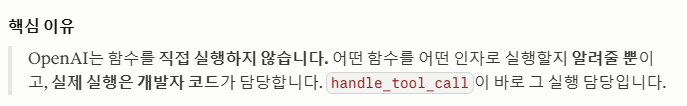

In [ ]:
def chat(message, history):
    # Gradio에서 전달된 대화 기록을 OpenAI 형식으로 변환
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    
    # 시스템 메시지 + 대화 기록 + 새 사용자 메시지를 합쳐 전체 메시지 구성
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    
    # 1단계 요청: OpenAI에 메시지 전송 (tools 포함)
    response = openai.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    # OpenAI가 툴 호출이 필요하다고 판단한 경우
    if response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message       # OpenAI의 툴 호출 요청 메시지 추출
        response = handle_tool_call(message)         # 실제 함수 실행 후 결과 획득
        messages.append(message)                     # 툴 호출 요청을 대화 기록에 추가
        messages.append(response)                    # 툴 실행 결과를 대화 기록에 추가
        
        # 2단계 요청: 툴 실행 결과를 포함하여 OpenAI에 재요청 (최종 답변 생성)
        response = openai.chat.completions.create(model=MODEL, messages=messages)
    
    # 최종 응답 텍스트 반환
    return response.choices[0].message.content

In [44]:
gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


## [개선] 단일 실행 문제점 

2가지 목적지 질의시 문제점 개선

In [45]:
def handle_tool_calls(message):
    responses = []  # 여러 툴 호출 결과를 담을 리스트
    
    for tool_call in message.tool_calls:  # 모든 툴 호출을 순회
        
        if tool_call.function.name == "get_ticket_price":  # 호출된 함수가 가격 조회인지 확인
            arguments = json.loads(tool_call.function.arguments)  # JSON 문자열을 딕셔너리로 변환
            city = arguments.get('destination_city')               # 목적지 도시 추출
            price_details = get_ticket_price(city)                 # 실제 가격 조회 함수 실행
            
            responses.append({
                "role": "tool",                # 역할: 툴 실행 결과임을 명시
                "content": price_details,      # 내용: 조회된 가격 정보
                "tool_call_id": tool_call.id   # 어떤 툴 호출에 대한 결과인지 연결
            })
            
    return responses  # 모든 툴 실행 결과 리스트 반환

In [46]:
def chat(message, history):
    # Gradio에서 전달된 대화 기록을 OpenAI 형식으로 변환
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    
    # 시스템 메시지 + 대화 기록 + 새 사용자 메시지를 합쳐 전체 메시지 구성
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    
    # 1단계 요청: tools 포함하여 OpenAI에 전송
    response = openai.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    # OpenAI가 툴 호출이 필요하다고 판단한 경우
    if response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message      # OpenAI의 툴 호출 요청 메시지 추출
        responses = handle_tool_calls(message)      # 모든 툴 실행 후 결과 리스트 획득
        messages.append(message)                    # 툴 호출 요청을 대화 기록에 추가
        messages.extend(responses)                  # 툴 실행 결과들을 대화 기록에 개별 추가
        
        # 2단계 요청: 툴 실행 결과를 포함하여 OpenAI에 재요청 (최종 답변 생성)
        response = openai.chat.completions.create(model=MODEL, messages=messages)
    
    # 최종 응답 텍스트 반환
    return response.choices[0].message.content

In [47]:
gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


Tool called for city 런던
Tool called for city 파리


## [개선] 연쇄 툴 호출

In [48]:
def chat(message, history):
    # Gradio에서 전달된 대화 기록을 OpenAI 형식으로 변환
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    
    # 시스템 메시지 + 대화 기록 + 새 사용자 메시지를 합쳐 전체 메시지 구성
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    
    # 1단계 요청: tools 포함하여 OpenAI에 전송
    response = openai.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    # 툴 호출이 필요한 동안 계속 반복 (연쇄 툴 호출 처리)
    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message      # OpenAI의 툴 호출 요청 메시지 추출
        responses = handle_tool_calls(message)      # 모든 툴 실행 후 결과 리스트 획득
        messages.append(message)                    # 툴 호출 요청을 대화 기록에 추가
        messages.extend(responses)                  # 툴 실행 결과들을 대화 기록에 개별 추가
        
        # 툴 결과 포함하여 재요청 (tools 포함: 추가 툴 호출 가능)
        response = openai.chat.completions.create(model=MODEL, messages=messages, tools=tools)
    
    # finish_reason == "stop" 이면 while 종료 후 최종 응답 텍스트 반환
    return response.choices[0].message.content

In [ ]:
gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7865
* To create a public link, set `share=True` in `launch()`.


Tool called for city 런던
Tool called for city 파리


# END